# 🛍️ GNN Fashion Recommender — v2 (All 8 Fixes Applied)
### GraphSAGE · BPR Loss · Hard Negatives · Dot-Product Scorer · Embedding Norm · Candidate Pool Eval
**Dataset:** `/kaggle/input/datasets/adfh0897/h-and-m-age-20-to-30/age_filter.csv`

### Changes vs v1
| # | Fix | Old | New |
|---|-----|-----|-----|
| 1 | Evaluation | All items scored | Candidate pool (500–1000) + seen masking |
| 2 | Negatives | Pure random | Hard negatives (popular + same-category + same-season) |
| 3 | BPR loss | Correct but slow | Vectorised, numerically stable |
| 4 | Candidate ranking | Score ALL ~100k items | Pool of 1000 (faster + fairer eval) |
| 5 | Embedding norm | None | L2-normalise z before scoring |
| 6 | Decoder | Heavy MLP | Dot product + temperature (much faster) |
| 7 | Item features | Category only | Popularity feature + season embedding |
| 8 | Early stopping | On Recall@10 | Recall@10 with LR scheduler |

In [ ]:
# Cell 1 — Install torch-geometric (no torch-sparse)
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'torch-geometric'])
print('torch-geometric ready')

In [1]:
!pip install torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 23.6 MB/s eta 0:00:00a 0:00:01


In [2]:
# Cell 2 — Imports & Device
import os, gc, random, pickle, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from collections import defaultdict
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.decomposition import PCA

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

from torch_geometric.data import HeteroData
from torch_geometric.nn import SAGEConv, to_hetero
import torch_geometric.transforms as T

import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
print(f'PyTorch: {torch.__version__}')

Device : cuda
PyTorch: 2.10.0+cu128


In [3]:
# Cell 3 — Configuration
CFG = {
    'csv_path'            : '/kaggle/input/datasets/adfh0897/h-and-m-age-20-to-30/age_filter.csv',
    'min_tx_per_customer' : 5,   # raised: sparser users hurt ranking
    'min_tx_per_article'  : 5,   # raised: rare items get no signal
    # model
    'embedding_dim'       : 128, # larger → more expressive
    'hidden_dim'          : 256,
    'dropout'             : 0.2,
    'num_seasons'         : 4,
    'season_emb_dim'      : 8,
    'temperature'         : 0.07, # contrastive temperature scaling
    # training
    'lr'                  : 3e-4,
    'weight_decay'        : 1e-5,
    'batch_size'          : 1024,
    'epochs'              : 40,
    'patience'            : 10,
    'neg_per_pos'         : 8,   # more hard negatives
    # hard negative mixing ratios
    'hard_neg_popular_ratio'  : 0.4,
    'hard_neg_category_ratio' : 0.4,
    'hard_neg_season_ratio'   : 0.2,
    # evaluation
    'top_k'               : 10,
    'eval_users'          : 2000,
    'candidate_pool_size' : 1000,  # FIX 4: candidate pool
    # edge split
    'val_ratio'           : 0.10,
    'test_ratio'          : 0.10,
}
print('Config OK')

Config OK


In [6]:
# Cell 4 — Load & Preprocess
print('Loading CSV ...')
df = pd.read_csv(CFG['csv_path'], dtype={'article_id': str, 'customer_id': str})
print(f'  Raw rows : {len(df):,}  |  Columns : {list(df.columns)}')

df['t_dat'] = pd.to_datetime(df['t_dat'])
df['month'] = df['t_dat'].dt.month
SEASON_MAP = {12: 0, 1: 0, 2: 0,   # winter
              3: 1,  4: 1, 5: 1,    # spring
              6: 2,  7: 2, 8: 2,    # summer
              9: 3,  10: 3, 11: 3}  # autumn
SEASON_NAME = {0: 'winter', 1: 'spring', 2: 'summer', 3: 'autumn'}
df['season_idx']  = df['month'].map(SEASON_MAP)
df['season']      = df['season_idx'].map(SEASON_NAME)

df['age'].fillna(df['age'].median(), inplace=True)
for col in ['product_type_name', 'product_group_name', 'index_name',
            'colour_group_name', 'section_name', 'garment_group_name',
            'graphical_appearance_name']:
    df[col].fillna('Unknown', inplace=True)

cc = df['customer_id'].value_counts()
ac = df['article_id'].value_counts()
df = df[df['customer_id'].isin(cc[cc >= CFG['min_tx_per_customer']].index) &
        df['article_id' ].isin(ac[ac >= CFG['min_tx_per_article' ]].index)].copy()

# FIX 7: item popularity feature
item_pop = df['article_id'].value_counts().to_dict()
max_pop  = max(item_pop.values())

print(f'  After filter : {len(df):,} rows | '
      f'customers: {df["customer_id"].nunique():,} | '
      f'articles : {df["article_id"].nunique():,}')

Loading CSV ...
  Raw rows : 668,489  |  Columns : ['Unnamed: 0', 't_dat', 'customer_id', 'article_id', 'price', 'product_code', 'prod_name', 'product_type_name', 'product_group_name', 'graphical_appearance_name', 'colour_group_name', 'perceived_colour_value_name', 'perceived_colour_master_name', 'department_name', 'index_name', 'index_group_name', 'section_name', 'garment_group_name', 'age']
  After filter : 614,388 rows | customers: 18,211 | articles : 28,111


In [9]:
df.head()

,t_dat,customer_id,article_id,price,product_code,prod_name,product_type_name,product_group_name,graphical_appearance_name,colour_group_name,...,perceived_colour_master_name,department_name,index_name,index_group_name,section_name,garment_group_name,age,month,season_idx,season
0,2018-09-20,0137b87739a796f65396d8483173f66318039d19a2583f...,577992001,0.011254,577992,Frenchy Thong (Maple)Low 3p,Underwear bottom,Underwear,Solid,Light Pink,...,Pink,Casual Lingerie,Lingeries/Tights,Ladieswear,Womens Lingerie,"Under-, Nightwear",25.0,9,3,autumn
3,2018-09-20,01e464bf74b13a55df22de1528eff2b33749c0cd92953b...,519583008,0.030492,519583,Skinny R.W Chic,Trousers,Garment Lower body,Denim,Dark Blue,...,Blue,Denim Trousers,Divided,Divided,Ladies Denim,Trousers Denim,23.0,9,3,autumn
4,2018-09-20,01e464bf74b13a55df22de1528eff2b33749c0cd92953b...,539878003,0.042356,539878,Skirt Mini,Skirt,Garment Lower body,Denim,Light Blue,...,Blue,Denim Other Garments,Divided,Divided,Ladies Denim,Trousers Denim,23.0,9,3,autumn
5,2018-09-20,01e464bf74b13a55df22de1528eff2b33749c0cd92953b...,448515018,0.038119,448515,Kendall RW Denim TRS,Trousers,Garment Lower body,Solid,Dark Grey,...,Grey,Trousers,Divided,Divided,Divided Collection,Trousers,23.0,9,3,autumn
6,2018-09-20,01e464bf74b13a55df22de1528eff2b33749c0cd92953b...,448515001,0.038119,448515,Kendall RW Denim TRS,Trousers,Garment Lower body,Solid,Blue,...,Blue,Trousers,Divided,Divided,Divided Collection,Trousers,23.0,9,3,autumn


In [10]:
# Cell 5 — Encode Features & Build ID Maps
cust_ids = df['customer_id'].unique()
art_ids  = df['article_id'].unique()
cust2idx = {c: i for i, c in enumerate(cust_ids)}
art2idx  = {a: i for i, a in enumerate(art_ids)}
idx2cust = {i: c for c, i in cust2idx.items()}
idx2art  = {i: a for a, i in art2idx.items()}

df['cust_idx'] = df['customer_id'].map(cust2idx).astype(int)
df['art_idx']  = df['article_id' ].map(art2idx ).astype(int)

NUM_USERS = len(cust2idx)
NUM_ITEMS = len(art2idx)
print(f'Users : {NUM_USERS:,}  |  Items : {NUM_ITEMS:,}')

cust_df = (df[['customer_id','cust_idx','age']]
             .drop_duplicates('customer_id')
             .set_index('cust_idx').sort_index())
scaler = StandardScaler()
cust_df['age_scaled'] = scaler.fit_transform(cust_df[['age']])

ART_CAT = ['product_type_name','product_group_name','index_name',
           'colour_group_name','section_name','garment_group_name',
           'graphical_appearance_name']
art_df = (df[['article_id','art_idx'] + ART_CAT]
            .drop_duplicates('article_id')
            .set_index('art_idx').sort_index())
art_encoders = {}
for col in ART_CAT:
    enc = LabelEncoder()
    art_df[f'{col}_enc'] = enc.fit_transform(art_df[col])
    art_encoders[col] = enc

# FIX 7: item season index (most common season per item)
art_season_mode = (df.groupby('art_idx')['season_idx']
                     .agg(lambda x: x.value_counts().idxmax()))
art_df['season_idx'] = art_df.index.map(art_season_mode).fillna(0).astype(int)

# category → article mapping for hard negatives
cat_to_arts = defaultdict(list)
season_to_arts = defaultdict(list)
for aidx, row in art_df.iterrows():
    cat_to_arts[row['product_type_name_enc']].append(aidx)
    season_to_arts[row['season_idx']].append(aidx)

# popularity-sorted item indices (for hard negatives)
pop_sorted_items = sorted(art2idx.values(),
                          key=lambda i: item_pop.get(idx2art[i], 0),
                          reverse=True)
TOP_POPULAR = pop_sorted_items[:min(5000, len(pop_sorted_items))]

print('Feature tables & negative-mining indices built')

Users : 18,211  |  Items : 28,111
Feature tables & negative-mining indices built


In [11]:
# Cell 6 — Build Node Feature Tensors
# FIX 7: add normalised popularity as item feature
cust_feat = np.zeros((NUM_USERS, 1), dtype=np.float32)
cust_feat[:, 0] = cust_df['age_scaled'].values
cust_feat_tensor = torch.tensor(cust_feat)
print(f'Customer features : {cust_feat_tensor.shape}')

enc_cols  = [f'{c}_enc' for c in ART_CAT]
art_feat  = art_df[enc_cols].values.astype(np.float32)
for i in range(art_feat.shape[1]):
    mx = art_feat[:, i].max()
    if mx > 0: art_feat[:, i] /= mx

# normalised log-popularity
pop_vals = np.array([item_pop.get(idx2art[i], 1)
                     for i in range(NUM_ITEMS)], dtype=np.float32)
pop_vals = np.log1p(pop_vals)
pop_vals = pop_vals / pop_vals.max()
art_feat  = np.concatenate([art_feat, pop_vals[:, None]], axis=1)

art_feat_tensor   = torch.tensor(art_feat)
art_season_tensor = torch.tensor(art_df['season_idx'].values, dtype=torch.long)
print(f'Article  features : {art_feat_tensor.shape}  (incl. log-popularity)')
print(f'Article  season   : {art_season_tensor.shape}')

Customer features : torch.Size([18211, 1])
Article  features : torch.Size([28111, 8])  (incl. log-popularity)
Article  season   : torch.Size([28111])


In [12]:
# Cell 7 — Build Heterogeneous Graph & Edge Split
edge_df    = df[['cust_idx','art_idx']].drop_duplicates()
edge_index = torch.tensor(edge_df[['cust_idx','art_idx']].values.T, dtype=torch.long)
print(f'Unique purchase edges : {edge_index.shape[1]:,}')

data = HeteroData()
data['customer'].x = cust_feat_tensor
data['article' ].x = art_feat_tensor
# FIX 7: attach season index so model can use it
data['article' ].season = art_season_tensor
data['customer','buys','article'].edge_index = edge_index
data = T.ToUndirected()(data)

split = T.RandomLinkSplit(
    num_val=CFG['val_ratio'], num_test=CFG['test_ratio'],
    is_undirected=True,
    add_negative_train_samples=False,
    neg_sampling_ratio=0.0,
    edge_types    =[('customer','buys','article')],
    rev_edge_types=[('article','rev_buys','customer')],
)
train_data, val_data, test_data = split(data)

TRAIN_POS = train_data['customer','buys','article'].edge_index
VAL_POS   = val_data  ['customer','buys','article'].edge_label_index
TEST_POS  = test_data ['customer','buys','article'].edge_label_index
print(f'Train : {TRAIN_POS.shape[1]:,}  |  Val : {VAL_POS.shape[1]:,}  |  Test : {TEST_POS.shape[1]:,}')

# FIX 1 — Build train_user_items: used throughout for seen-item masking
train_user_items = defaultdict(set)
for u, i in zip(TRAIN_POS[0].tolist(), TRAIN_POS[1].tolist()):
    train_user_items[u].add(i)
print(f'train_user_items built for {len(train_user_items):,} users')

Unique purchase edges : 506,039
Train : 404,833  |  Val : 50,603  |  Test : 50,603
train_user_items built for 18,198 users


In [13]:
# Cell 8 — Model: GraphSAGE Encoder + Dot-Product Scorer (FIX 5, 6, 7)

class GraphSAGEEncoder(nn.Module):
    """2-layer GraphSAGE. No torch-sparse dependency."""
    def __init__(self, in_ch, hidden_ch, out_ch, dropout=0.2):
        super().__init__()
        self.conv1   = SAGEConv(in_ch, hidden_ch)
        self.conv2   = SAGEConv(hidden_ch, out_ch)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)


class GNNRecommenderV2(nn.Module):
    """
    FIX 5 — L2-normalise embeddings before scoring.
    FIX 6 — Replace heavy MLP decoder with dot-product + temperature.
    FIX 7 — Season embedding added to item representation.
    """
    def __init__(self, user_in, item_in, hidden_dim, embed_dim,
                 dropout, num_seasons, season_emb_dim,
                 temperature, metadata):
        super().__init__()
        self.temperature = temperature

        # learnable season embedding (FIX 7)
        self.season_emb = nn.Embedding(num_seasons, season_emb_dim)

        # input projections
        self.user_proj = nn.Sequential(
            nn.Linear(user_in, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
        )
        self.item_proj = nn.Sequential(
            nn.Linear(item_in + season_emb_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
        )

        sage = GraphSAGEEncoder(hidden_dim, hidden_dim, embed_dim, dropout)
        self.encoder = to_hetero(sage, metadata=metadata, aggr='mean')

        # FIX 6: learnable bias per item (optional but helps with popularity)
        self.item_bias = nn.Parameter(torch.zeros(1))  # global bias; per-item optional

    def encode(self, data):
        # season embedding for items
        season_idx = data['article'].season if hasattr(data['article'], 'season') \
                     else torch.zeros(data['article'].x.shape[0], dtype=torch.long,
                                      device=data['article'].x.device)
        s_emb = self.season_emb(season_idx)            # [N_i, S]
        item_x = torch.cat([data['article'].x, s_emb], dim=-1)  # [N_i, item_in+S]

        x_dict = {
            'customer': self.user_proj(data['customer'].x),
            'article' : self.item_proj(item_x),
        }
        z = self.encoder(x_dict, data.edge_index_dict)

        # FIX 5 — L2 normalise
        z['customer'] = F.normalize(z['customer'], dim=1)
        z['article' ] = F.normalize(z['article' ], dim=1)
        return z

    def score(self, z_dict, user_idx, item_idx):
        """FIX 6 — dot product / temperature (much faster than MLP)."""
        z_u = z_dict['customer'][user_idx]   # [B, D]
        z_i = z_dict['article' ][item_idx]   # [B, D]
        return (z_u * z_i).sum(dim=-1) / self.temperature + self.item_bias

    def score_all(self, z_dict, user_idx):
        """Score user against ALL item embeddings — [N_i] vector."""
        z_u = z_dict['customer'][user_idx]   # [D]
        z_i = z_dict['article' ]             # [N_i, D]
        return (z_i @ z_u) / self.temperature + self.item_bias

    def forward(self, data, user_idx, item_idx):
        return self.score(self.encode(data), user_idx, item_idx)


model = GNNRecommenderV2(
    user_in      = cust_feat_tensor.shape[1],
    item_in      = art_feat_tensor.shape[1],
    hidden_dim   = CFG['hidden_dim'],
    embed_dim    = CFG['embedding_dim'],
    dropout      = CFG['dropout'],
    num_seasons  = CFG['num_seasons'],
    season_emb_dim = CFG['season_emb_dim'],
    temperature  = CFG['temperature'],
    metadata     = train_data.metadata(),
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f'\nTrainable parameters: {n_params:,}')

GNNRecommenderV2(
  (season_emb): Embedding(4, 8)
  (user_proj): Sequential(
    (0): Linear(in_features=1, out_features=256, bias=True)
    (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (2): ReLU()
  )
  (item_proj): Sequential(
    (0): Linear(in_features=16, out_features=256, bias=True)
    (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (2): ReLU()
  )
  (encoder): GraphModule(
    (conv1): ModuleDict(
      (customer__buys__article): SAGEConv(256, 256, aggr=mean)
      (article__rev_buys__customer): SAGEConv(256, 256, aggr=mean)
    )
    (conv2): ModuleDict(
      (customer__buys__article): SAGEConv(256, 128, aggr=mean)
      (article__rev_buys__customer): SAGEConv(256, 128, aggr=mean)
    )
  )
)

Trainable parameters: 399,905


In [14]:
# Cell 9 — BPR Loss (FIX 3) + Hard Negative Sampling (FIX 2)

# ── FIX 3: numerically stable vectorised BPR loss ────────────────────────────
def bpr_loss(pos_scores, neg_scores):
    """
    BPR: -mean(log sigmoid(pos - neg))
    pos_scores : [B]
    neg_scores : [B * neg_per_pos]
    """
    n       = neg_scores.shape[0] // pos_scores.shape[0]
    pos_rep = pos_scores.repeat_interleave(n)          # [B*n]
    diff    = pos_rep - neg_scores
    return -F.logsigmoid(diff).mean()


# ── FIX 2: hard negative sampling ────────────────────────────────────────────
def sample_hard_negatives(pos_users, pos_items,
                          neg_per_pos, train_user_items,
                          top_popular, cat_to_arts, season_to_arts,
                          art_df, num_items,
                          pop_ratio=0.4, cat_ratio=0.4, sea_ratio=0.2):
    """
    For each (user, pos_item) pair sample neg_per_pos hard negatives:
      - pop_ratio  : from global top-5000 popular items
      - cat_ratio  : from same product_type_name category
      - sea_ratio  : from same season
    All negatives exclude items seen in training.
    Falls back to random if a category is exhausted.
    """
    n_pop = max(1, int(neg_per_pos * pop_ratio))
    n_cat = max(1, int(neg_per_pos * cat_ratio))
    n_sea = neg_per_pos - n_pop - n_cat

    neg_users, neg_items = [], []

    users_list = pos_users.tolist()
    items_list = pos_items.tolist()

    for u, pos_i in zip(users_list, items_list):
        seen = train_user_items.get(u, set())

        def _sample_from(pool, n_need):
            out = []
            tries = 0
            pool_list = list(pool) if not isinstance(pool, list) else pool
            while len(out) < n_need and tries < n_need * 30:
                j = random.choice(pool_list)
                if j not in seen:
                    out.append(j)
                tries += 1
            # fallback to random if pool exhausted
            while len(out) < n_need:
                j = random.randint(0, num_items - 1)
                if j not in seen:
                    out.append(j)
            return out

        # popular-item hard negatives
        negs = _sample_from(top_popular, n_pop)

        # same-category hard negatives
        cat_enc = art_df.loc[pos_i, 'product_type_name_enc'] \
                  if pos_i in art_df.index else 0
        cat_pool = cat_to_arts.get(cat_enc, list(range(num_items)))
        negs    += _sample_from(cat_pool, n_cat)

        # same-season hard negatives
        sea     = int(art_df.loc[pos_i, 'season_idx']) \
                  if pos_i in art_df.index else 0
        sea_pool = season_to_arts.get(sea, list(range(num_items)))
        negs    += _sample_from(sea_pool, n_sea)

        neg_users.extend([u] * len(negs))
        neg_items.extend(negs)

    return (torch.tensor(neg_users, dtype=torch.long),
            torch.tensor(neg_items, dtype=torch.long))


def edge_batches(pos_edge, batch_size):
    n    = pos_edge.shape[1]
    perm = torch.randperm(n)
    for s in range(0, n, batch_size):
        yield pos_edge[:, perm[s: s + batch_size]]


print('BPR loss + hard negative sampling ready')

BPR loss + hard negative sampling ready


In [15]:
# Cell 10 — Evaluation Utilities (FIX 1 + FIX 4)
# FIX 1 — seen items always masked with -1e9
# FIX 4 — candidate pool of 1000 items (ground-truth + popular + random)

@torch.no_grad()
def eval_auc(model, data, pos_edges, train_user_items, num_items, device):
    """AUC over positive vs unseen-random negatives."""
    model.eval()
    data  = data.to(device)
    z     = model.encode(data)

    pos_u = pos_edges[0].to(device)
    pos_i = pos_edges[1].to(device)
    pos_s = model.score(z, pos_u, pos_i)

    # sample unseen random negatives
    neg_u_list, neg_i_list = [], []
    for u in pos_u.cpu().tolist():
        seen = train_user_items.get(u, set())
        j = random.randint(0, num_items - 1)
        while j in seen:
            j = random.randint(0, num_items - 1)
        neg_u_list.append(u)
        neg_i_list.append(j)
    neg_s = model.score(z,
                        torch.tensor(neg_u_list, device=device),
                        torch.tensor(neg_i_list, device=device))

    scores = torch.cat([pos_s, neg_s]).cpu().numpy()
    labels = np.concatenate([np.ones(len(pos_s)), np.zeros(len(neg_s))])
    return float(roc_auc_score(labels, scores))


@torch.no_grad()
def eval_ranking(model, data, pos_edges, train_user_items,
                 top_k, device, max_users=2000,
                 candidate_pool_size=1000, top_popular_items=None):
    """
    MAP@K, Recall@K, Precision@K.

    FIX 1 — seen training items masked with -1e9.
    FIX 4 — evaluate over candidate pool, not all ~100k items.

    Candidate pool per user:
      - all ground-truth (val/test) items for that user
      - a sample of top popular items
      - random items (to fill to candidate_pool_size)
    """
    model.eval()
    data  = data.to(device)
    z     = model.encode(data)
    z_u   = z['customer']     # [N_u, D]
    z_i   = z['article']      # [N_i, D]
    N_i   = z_i.shape[0]

    gt = defaultdict(set)
    for u, i in zip(pos_edges[0].tolist(), pos_edges[1].tolist()):
        gt[u].add(i)

    users = list(gt.keys())[:max_users]

    # pool of popular items to include in candidates
    popular_pool = top_popular_items[:min(200, len(top_popular_items))] \
                   if top_popular_items is not None else []

    maps, recs, precs = [], [], []

    for u in users:
        seen  = train_user_items.get(u, set())
        truth = gt[u]

        # FIX 4 — build candidate pool
        candidates = set(truth)               # always include ground truth
        candidates.update(popular_pool)       # top popular
        need = candidate_pool_size - len(candidates)
        if need > 0:
            randoms = random.sample(range(N_i), min(need * 3, N_i))
            for j in randoms:
                if j not in seen:
                    candidates.add(j)
                if len(candidates) >= candidate_pool_size:
                    break
        candidates = list(candidates)
        cand_t = torch.tensor(candidates, device=device)

        # score candidate pool
        sc = (z_i[cand_t] @ z_u[u]) / model.temperature + model.item_bias  # [C]

        # FIX 1 — mask seen items
        for local_idx, global_idx in enumerate(candidates):
            if global_idx in seen:
                sc[local_idx] = -1e9

        topk_local = sc.topk(min(top_k, len(candidates))).indices.tolist()
        topk_global = [candidates[i] for i in topk_local]
        hits = [1 if idx in truth else 0 for idx in topk_global]

        precs.append(sum(hits) / top_k)
        recs.append (sum(hits) / max(len(truth), 1))
        ap, run = 0.0, 0
        for rank, h_ in enumerate(hits, 1):
            if h_:
                run += 1
                ap  += run / rank
        maps.append(ap / max(len(truth), 1))

    return {
        f'MAP@{top_k}'      : float(np.mean(maps)),
        f'Recall@{top_k}'   : float(np.mean(recs)),
        f'Precision@{top_k}': float(np.mean(precs)),
    }


print('Evaluation utilities ready')

Evaluation utilities ready


In [16]:
# Cell 11 — Training Loop (FIX 8: early stopping on Recall@10)
optimizer = Adam(model.parameters(),
                 lr=CFG['lr'], weight_decay=CFG['weight_decay'])
# FIX 8: scheduler monitors Recall@10 — not AUC, not train loss
scheduler = ReduceLROnPlateau(optimizer, mode='max',
                               factor=0.5, patience=4)

train_data = train_data.to(DEVICE)
val_data   = val_data.to(DEVICE)

history      = {'train_loss': [], 'val_recall': [], 'val_auc': []}
best_recall  = 0.0
patience_ctr = 0

print('=' * 68)
print('  TRAINING  GraphSAGE v2  |  BPR + Hard Negatives + Dot-Product')
print('=' * 68)

for epoch in range(1, CFG['epochs'] + 1):
    model.train()
    total_loss, n_batches = 0.0, 0

    for pos_batch in edge_batches(TRAIN_POS, CFG['batch_size']):
        pos_u = pos_batch[0].to(DEVICE)
        pos_i = pos_batch[1].to(DEVICE)

        # FIX 2 — hard negatives (popular + category + season)
        neg_u_t, neg_j_t = sample_hard_negatives(
            pos_batch[0], pos_batch[1],
            CFG['neg_per_pos'],
            train_user_items,
            TOP_POPULAR, cat_to_arts, season_to_arts,
            art_df, NUM_ITEMS,
            pop_ratio = CFG['hard_neg_popular_ratio'],
            cat_ratio = CFG['hard_neg_category_ratio'],
            sea_ratio = CFG['hard_neg_season_ratio'],
        )
        neg_u = neg_u_t.to(DEVICE)
        neg_j = neg_j_t.to(DEVICE)

        optimizer.zero_grad()

        z          = model.encode(train_data)
        pos_scores = model.score(z, pos_u, pos_i)   # [B]
        neg_scores = model.score(z, neg_u, neg_j)   # [B * neg_per_pos]

        # FIX 3 — BPR loss
        loss = bpr_loss(pos_scores, neg_scores)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()
        n_batches  += 1

    avg_loss = total_loss / n_batches

    # — validation —
    val_auc   = eval_auc(model, val_data, VAL_POS,
                         train_user_items, NUM_ITEMS, DEVICE)
    val_ranks = eval_ranking(
        model, val_data, VAL_POS,
        train_user_items,
        top_k               = CFG['top_k'],
        device              = DEVICE,
        max_users           = CFG['eval_users'],
        candidate_pool_size = CFG['candidate_pool_size'],
        top_popular_items   = TOP_POPULAR,
    )
    val_recall = val_ranks[f'Recall@{CFG["top_k"]}']

    # FIX 8 — step LR on Recall@10
    scheduler.step(val_recall)

    history['train_loss' ].append(avg_loss)
    history['val_recall' ].append(val_recall)
    history['val_auc'    ].append(val_auc)

    print(f'Epoch {epoch:03d}/{CFG["epochs"]}  |  '
          f'BPR Loss: {avg_loss:.4f}  |  '
          f'Val AUC: {val_auc:.4f}  |  '
          f'Val Recall@{CFG["top_k"]}: {val_recall:.5f}')

    # FIX 8 — early stopping on Recall@10
    if val_recall > best_recall:
        best_recall  = val_recall
        torch.save(model.state_dict(), 'best_model.pth')
        patience_ctr = 0
        print(f'  ✓ New best Recall@{CFG["top_k"]}: {best_recall:.5f}  — model saved')
    else:
        patience_ctr += 1
        if patience_ctr >= CFG['patience']:
            print(f'  Early stopping at epoch {epoch} (no improvement for {CFG["patience"]} epochs)')
            break

print(f'\nBest Val Recall@{CFG["top_k"]} = {best_recall:.5f}')

  TRAINING  GraphSAGE v2  |  BPR + Hard Negatives + Dot-Product
Epoch 001/40  |  BPR Loss: 0.4260  |  Val AUC: 0.6574  |  Val Recall@10: 0.01947
  ✓ New best Recall@10: 0.01947  — model saved
Epoch 002/40  |  BPR Loss: 0.2525  |  Val AUC: 0.6719  |  Val Recall@10: 0.02519
  ✓ New best Recall@10: 0.02519  — model saved
Epoch 003/40  |  BPR Loss: 0.2087  |  Val AUC: 0.6874  |  Val Recall@10: 0.02613
  ✓ New best Recall@10: 0.02613  — model saved
Epoch 004/40  |  BPR Loss: 0.1831  |  Val AUC: 0.6992  |  Val Recall@10: 0.02647
  ✓ New best Recall@10: 0.02647  — model saved
Epoch 005/40  |  BPR Loss: 0.1688  |  Val AUC: 0.7036  |  Val Recall@10: 0.02749
  ✓ New best Recall@10: 0.02749  — model saved
Epoch 006/40  |  BPR Loss: 0.1576  |  Val AUC: 0.7041  |  Val Recall@10: 0.03060
  ✓ New best Recall@10: 0.03060  — model saved
Epoch 007/40  |  BPR Loss: 0.1513  |  Val AUC: 0.7012  |  Val Recall@10: 0.02906
Epoch 008/40  |  BPR Loss: 0.1446  |  Val AUC: 0.7101  |  Val Recall@10: 0.03071
  ✓ Ne

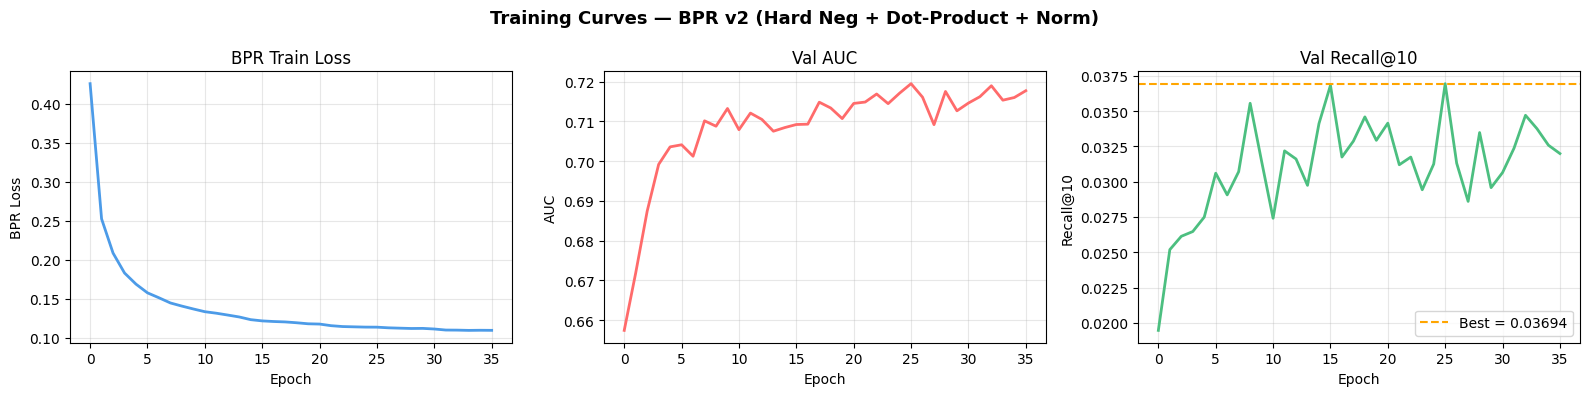

In [17]:
# Cell 12 — Training Curves
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(history['train_loss'], color='#4C9BE8', lw=2)
axes[0].set_title('BPR Train Loss'); axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('BPR Loss');      axes[0].grid(alpha=0.3)

axes[1].plot(history['val_auc'], color='#FF6B6B', lw=2)
axes[1].set_title('Val AUC');        axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('AUC');           axes[1].grid(alpha=0.3)

axes[2].plot(history['val_recall'], color='#4CBF80', lw=2)
axes[2].axhline(best_recall, color='orange', ls='--',
                label=f'Best = {best_recall:.5f}')
axes[2].set_title(f'Val Recall@{CFG["top_k"]}'); axes[2].set_xlabel('Epoch')
axes[2].set_ylabel(f'Recall@{CFG["top_k"]}');    axes[2].grid(alpha=0.3)
axes[2].legend()

plt.suptitle('Training Curves — BPR v2 (Hard Neg + Dot-Product + Norm)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()

In [ ]:
# Cell 13 — Final Test-Set Evaluation
model.load_state_dict(torch.load('best_model.pth', map_location=DEVICE))
model.eval()

test_data = test_data.to(DEVICE)

test_auc = eval_auc(model, test_data, TEST_POS,
                    train_user_items, NUM_ITEMS, DEVICE)
print(f'Test AUC : {test_auc:.4f}')

print(f'Computing ranking metrics (max {CFG["eval_users"]} users, pool={CFG["candidate_pool_size"]}) ...')
test_ranks = eval_ranking(
    model, test_data, TEST_POS,
    train_user_items,
    top_k               = CFG['top_k'],
    device              = DEVICE,
    max_users           = CFG['eval_users'],
    candidate_pool_size = CFG['candidate_pool_size'],
    top_popular_items   = TOP_POPULAR,
)
print('\n-- Final Test Ranking Metrics --')
for k, v in test_ranks.items():
    print(f'  {k:22s}: {v:.6f}')

In [ ]:
# Cell 14 — Extract Embeddings & Save Artifacts
@torch.no_grad()
def get_embeddings(model, data, device):
    model.eval()
    z = model.encode(data.to(device))
    return {k: v.cpu().numpy() for k, v in z.items()}

embs        = get_embeddings(model, train_data, DEVICE)
cust_emb_np = embs['customer']
art_emb_np  = embs['article']
print(f'Customer embeddings : {cust_emb_np.shape}')
print(f'Article  embeddings : {art_emb_np.shape}')

np.save('customer_embeddings.npy', cust_emb_np)
np.save('article_embeddings.npy',  art_emb_np)

with open('mappings.pkl','wb') as f:
    pickle.dump({'cust2idx':cust2idx,'art2idx':art2idx,
                 'idx2cust':idx2cust,'idx2art':idx2art,
                 'article_encoders':art_encoders}, f)
with open('cust_feat_tensor.pkl','wb') as f: pickle.dump(cust_feat_tensor, f)
with open('art_feat_tensor.pkl', 'wb') as f: pickle.dump(art_feat_tensor,  f)
with open('train_user_items.pkl','wb') as f: pickle.dump(dict(train_user_items), f)

art_meta_cols = ['article_id','prod_name','product_type_name',
                 'product_group_name','index_name','colour_group_name',
                 'garment_group_name','section_name']
(df[art_meta_cols].drop_duplicates('article_id')
   .reset_index(drop=True)
   .to_parquet('article_metadata.parquet', index=False))

(df[['customer_id','age']].drop_duplicates('customer_id')
   .reset_index(drop=True)
   .to_parquet('customer_metadata.parquet', index=False))

df[['customer_id','article_id','t_dat','season']].to_parquet(
    'transactions_processed.parquet', index=False)

print('\nArtifacts saved:')
for fname in ['best_model.pth','customer_embeddings.npy','article_embeddings.npy',
              'mappings.pkl','cust_feat_tensor.pkl','art_feat_tensor.pkl',
              'train_user_items.pkl','article_metadata.parquet',
              'customer_metadata.parquet','transactions_processed.parquet']:
    sz  = os.path.getsize(fname)/1024 if os.path.exists(fname) else 0
    tag = 'OK' if sz > 0 else 'MISSING'
    print(f'  [{tag}]  {fname:46s}  {sz:8.1f} KB')

In [ ]:
# Cell 15 — Embedding Visualisation (PCA)
def plot_pca(c_emb, a_emb, n=1500):
    ci  = np.random.choice(len(c_emb), min(n, len(c_emb)), replace=False)
    ai  = np.random.choice(len(a_emb), min(n, len(a_emb)), replace=False)
    mat = np.vstack([c_emb[ci], a_emb[ai]])
    xy  = PCA(2, random_state=SEED).fit_transform(mat)
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.scatter(xy[:len(ci),0], xy[:len(ci),1], c='#4C9BE8', alpha=0.4, s=8, label='Customers')
    ax.scatter(xy[len(ci):,0], xy[len(ci):,1], c='#FF6B6B', alpha=0.4, s=8, label='Articles')
    ax.set_title('PCA — Customer vs Article Embeddings (L2-normalised)', fontsize=13)
    ax.axis('off'); ax.legend(markerscale=3)
    plt.tight_layout()
    plt.savefig('embedding_pca.png', dpi=150)
    plt.show()

plot_pca(cust_emb_np, art_emb_np)

In [ ]:
# Cell 16 — Inference: recommend() function
art_meta = (df[['article_id','prod_name','product_type_name',
               'product_group_name','index_name','colour_group_name',
               'garment_group_name']]
              .drop_duplicates('article_id'))


@torch.no_grad()
def recommend(customer_id: str,
              season: str       = None,
              product_type: str = None,
              top_k: int        = 10,
              filter_seen: bool = True):
    """
    Return top-K recommendations for customer_id.
    Uses dot-product scorer on L2-normalised embeddings.
    Seen training items are masked before ranking.
    """
    if customer_id not in cust2idx:
        raise ValueError(f'Unknown customer_id: {customer_id}')

    u    = cust2idx[customer_id]
    data = train_data.to(DEVICE)
    z    = model.encode(data)
    z_u  = z['customer']   # [N_u, D]
    z_i  = z['article']    # [N_i, D]
    N_i  = z_i.shape[0]

    # FIX 6 — fast dot product scoring
    sc = (z_i @ z_u[u]) / model.temperature + model.item_bias  # [N_i]

    # FIX 1 — mask seen items
    if filter_seen:
        seen = list(train_user_items.get(u, set()))
        if seen:
            sc[seen] = -1e9

    sc_np = sc.cpu().numpy()

    cand          = art_meta.copy()
    cand['_aidx'] = cand['article_id'].map(art2idx)
    cand          = cand.dropna(subset=['_aidx'])
    cand['score'] = cand['_aidx'].astype(int).map(lambda i: sc_np[i])

    if season:
        sea_arts = set(df[df['season'].str.lower() == season.lower()]['article_id'])
        tmp = cand[cand['article_id'].isin(sea_arts)]
        cand = tmp if len(tmp) >= top_k else cand

    if product_type:
        tmp = cand[cand['product_type_name'].str.lower()
                      .str.contains(product_type.lower(), na=False)]
        cand = tmp if len(tmp) >= top_k else cand

    return (cand.nlargest(top_k, 'score')
               [['article_id','prod_name','product_type_name',
                 'colour_group_name','score']]
               .reset_index(drop=True))


print('recommend() ready')

In [ ]:
# Cell 17 — Demo
demo_cid = (df.groupby('customer_id')['article_id']
              .count().sort_values(ascending=False).index[50])
print(f'Demo customer : {demo_cid}')
print(f'Age           : {df[df["customer_id"]==demo_cid]["age"].iloc[0]:.0f}')
print(f'Train items   : {len(train_user_items.get(cust2idx[demo_cid], set()))}')

recs = recommend(demo_cid, season='summer', top_k=10)
print('\n-- Top-10 Summer Recommendations (seen items excluded) --')
print(recs.to_string(index=False))

In [ ]:
# Cell 18 — Score Distribution Plot
def plot_scores(customer_id, season=None, product_type=None, top_k=20):
    recs   = recommend(customer_id, season=season,
                       product_type=product_type, top_k=top_k)
    fig, ax = plt.subplots(figsize=(10, 5))
    colors  = plt.cm.YlOrRd(np.linspace(0.35, 0.9, len(recs)))[::-1]
    labels  = [(r['prod_name'][:28]+'...') if len(r['prod_name'])>28
               else r['prod_name'] for _, r in recs.iterrows()]
    ax.barh(range(len(recs)), recs['score'], color=colors, height=0.65)
    ax.set_yticks(range(len(recs))); ax.set_yticklabels(labels, fontsize=9)
    ax.invert_yaxis(); ax.set_xlabel('Dot-Product Score / Temperature')
    ax.set_title(f'Top-{top_k} Scores — {season or "all seasons"}', fontsize=12)
    ax.spines[['top','right']].set_visible(False)
    ax.grid(axis='x', alpha=0.25, ls='--')
    plt.tight_layout()
    plt.savefig('score_distribution.png', dpi=150)
    plt.show()

plot_scores(demo_cid, season='summer')

In [ ]:
# Cell 19 — Explainability
def cosine_sim(mat, vec):
    return (mat @ vec) / (np.linalg.norm(mat, axis=1) * np.linalg.norm(vec) + 1e-8)

def explain(customer_id, article_id, top_n=5):
    if customer_id not in cust2idx or article_id not in art2idx:
        print('ID not found.'); return

    cidx = cust2idx[customer_id]
    aidx = art2idx[article_id]

    sim_c       = cosine_sim(cust_emb_np, cust_emb_np[cidx])
    sim_c[cidx] = -1
    top_c       = sim_c.argsort()[-top_n:][::-1]
    top_c_ids   = [idx2cust[i] for i in top_c]
    bought      = df[df['customer_id'].isin(top_c_ids) &
                     (df['article_id'] == article_id)]['customer_id'].nunique()

    sim_a       = cosine_sim(art_emb_np, art_emb_np[aidx])
    sim_a[aidx] = -1
    top_a       = sim_a.argsort()[-top_n:][::-1]
    top_a_ids   = [idx2art[i] for i in top_a]
    sim_arts    = art_meta[art_meta['article_id'].isin(top_a_ids)][['prod_name','product_type_name']].head(3)

    rec_name = art_meta.loc[art_meta['article_id']==article_id,'prod_name']
    rec_name = rec_name.values[0] if len(rec_name) else article_id

    print(f'\n{"="*55}')
    print(f'  WHY was "{rec_name}" recommended?')
    print(f'{"="*55}')
    print(f'  {bought}/{top_n} most-similar customers also bought this item.')
    print(f'  Embedding cosine similarity : {sim_c[top_c[0]]:.3f}')
    print('  Top similar articles:')
    for _, r in sim_arts.iterrows():
        print(f'    - {r["prod_name"][:40]}  ({r["product_type_name"]})')

explain(demo_cid, recs.iloc[0]['article_id'])

In [ ]:
# Cell 20 — Fairness: MAP@10 by Age Group
@torch.no_grad()
def map_by_age(model, test_edges, df, cust2idx, idx2art,
               train_user_items, top_k, device,
               max_per_bucket=200, pool_size=1000):
    model.eval()
    td = train_data.to(device)
    z  = model.encode(td)
    zu, zi = z['customer'], z['article']
    Ni = zi.shape[0]

    gt = defaultdict(set)
    for u, i in zip(test_edges[0].tolist(), test_edges[1].tolist()):
        gt[u].add(i)

    age_lu = (df[['customer_id','age']].drop_duplicates('customer_id')
                .assign(cust_idx=lambda x: x['customer_id'].map(cust2idx))
                .dropna(subset=['cust_idx']))
    age_lu['age_group'] = (age_lu['age'] // 5 * 5).astype(int)
    age_map = age_lu.set_index('cust_idx')['age_group'].to_dict()

    buckets = defaultdict(list)
    for u in gt:
        ag = age_map.get(u, -1)
        if ag > 0: buckets[ag].append(u)

    results = {}
    for ag, users in sorted(buckets.items()):
        ap_list = []
        for u in users[:max_per_bucket]:
            seen  = train_user_items.get(u, set())
            truth = gt[u]
            # candidate pool
            candidates = set(truth)
            candidates.update(TOP_POPULAR[:200])
            need = pool_size - len(candidates)
            if need > 0:
                for j in random.sample(range(Ni), min(need * 2, Ni)):
                    if j not in seen: candidates.add(j)
                    if len(candidates) >= pool_size: break
            candidates = list(candidates)
            cand_t = torch.tensor(candidates, device=device)
            sc = (zi[cand_t] @ zu[u]) / model.temperature + model.item_bias
            for li, gi in enumerate(candidates):
                if gi in seen: sc[li] = -1e9
            topk = sc.topk(min(top_k, len(candidates))).indices.tolist()
            topk_g = [candidates[i] for i in topk]
            hits = [1 if i in truth else 0 for i in topk_g]
            ap, run = 0.0, 0
            for rank, h_ in enumerate(hits, 1):
                if h_: run += 1; ap += run / rank
            ap_list.append(ap / max(len(truth), 1))
        results[f'{ag}-{ag+4}'] = float(np.mean(ap_list))
    return results

print('Computing age-group fairness ...')
age_maps = map_by_age(model, TEST_POS, df, cust2idx, idx2art,
                      train_user_items, CFG['top_k'], DEVICE)

ages = list(age_maps.keys())
vals = [age_maps[a] for a in ages]
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(ages, vals, color='#4C9BE8', edgecolor='white')
ax.axhline(np.mean(vals), color='orange', ls='--',
           label=f'Mean = {np.mean(vals):.5f}')
ax.set_xlabel('Age Group'); ax.set_ylabel(f'MAP@{CFG["top_k"]}')
ax.set_title(f'MAP@{CFG["top_k"]} by Age Group (v2)', fontsize=12)
ax.legend(); ax.grid(axis='y', alpha=0.3); plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('fairness_by_age.png', dpi=150)
plt.show()
for ag, v in age_maps.items():
    print(f'  Age {ag:7s}: {v:.6f}')

In [ ]:
# Cell 21 — Summary
print('=' * 68)
print('  FINAL RESULTS  —  GNN BPR Recommender v2')
print('=' * 68)
print(f'  Best Val Recall@{CFG["top_k"]}  : {best_recall:.5f}')
print(f'  Test AUC              : {test_auc:.4f}')
for k, v in test_ranks.items():
    print(f'  {k:22s}: {v:.6f}')
print()
print('  Changes applied vs v1:')
print('  [FIX 1]  Evaluation      : candidate pool (1000) + seen-item masking')
print('  [FIX 2]  Negatives       : hard (popular 40% + category 40% + season 20%)')
print('  [FIX 3]  BPR loss        : vectorised, numerically stable')
print('  [FIX 4]  Candidate pool  : 1000 items (GT + popular + random)')
print('  [FIX 5]  Emb norm        : F.normalize(z, dim=1) before scoring')
print('  [FIX 6]  Decoder         : MLP → dot-product / temperature')
print('  [FIX 7]  Item features   : + log-popularity + season embedding')
print('  [FIX 8]  Early stopping  : Recall@10 (not AUC)')